# 02 — Crop Biji + Augmentasi Offline

Dua tahap pembentukan dataset pelatihan:

1. **Crop** tiap bounding box anotasi → `data/crops_raw/<split>/<kelas>/`
2. **Augmentasi offline** → `data/crops/<split>/<kelas>/` (siap latih)

Augmentasi dijalankan **sekali lalu dibekukan ke disk**, bukan on-the-fly tiap epoch. Alasannya reproducibility: dataset yang dilatih adalah berkas yang bisa dihitung, diperiksa, dan dilampirkan ke laporan.

Aturan yang tidak dilanggar: **hanya split `train` yang diaugmentasi.** Valid dan test disalin apa adanya supaya metrik diukur pada citra asli.

> **Verifikasi visual di bagian 6 jangan dilewati.** Validasi numerik tidak bisa menangkap `class_id` yang tertukar saat menganotasi.

## Setup

In [1]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: c:\Users\DZXP\Documents\ta-green-bean


In [2]:
import logging

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from configs.base_config import (
    ANNOTATED_DATA_DIR,
    AUGMENT_SPLITS,
    AUGMENTATION_MULTIPLIERS,
    CLASS_COLORS,
    CLASS_NAMES,
    COPY_SPLITS,
    CROPS_DIR,
    CROPS_RAW_DIR,
    RANDOM_SEED,
    SPLITS,
)
from src.analysis.style import apply_plot_style, class_palette
from src.data.crop_from_annotation import crop_beans_from_annotations
from src.data.offline_augmentation import build_dataset, format_augmentation_report
from src.training.imbalance import describe_imbalance
from src.utils.seed import set_seed

logging.basicConfig(level=logging.WARNING, format='%(levelname)s | %(message)s')
apply_plot_style()
set_seed(RANDOM_SEED)

print('multiplier augmentasi:', AUGMENTATION_MULTIPLIERS)
print('diaugmentasi :', AUGMENT_SPLITS)
print('hanya disalin:', COPY_SPLITS)

multiplier augmentasi: {'good': 1, 'black': 3, 'chipped': 3, 'dry_pods': 3, 'insect_damage': 3}
diaugmentasi : ('train',)
hanya disalin: ('valid', 'test')


## 1. Crop biji dari anotasi → `crops_raw`

In [3]:
stats_per_split = {}
for split in SPLITS:
    images_dir = ANNOTATED_DATA_DIR / split / 'images'
    labels_dir = ANNOTATED_DATA_DIR / split / 'labels'
    if not images_dir.is_dir() or not labels_dir.is_dir():
        print(f'{split}: DILEWATI ({images_dir} tidak ada)')
        continue

    stats = crop_beans_from_annotations(
        images_dir=images_dir,
        labels_dir=labels_dir,
        output_dir=CROPS_RAW_DIR / split,
        class_names=CLASS_NAMES,
    )
    stats_per_split[split] = stats
    print(f"{split}: {stats['num_images']} foto -> {stats['num_crops']} crop")

crop train: 100%|##########| 18/18 [00:01<00:00, 12.25foto/s]


train: 18 foto -> 2162 crop


crop valid: 100%|##########| 6/6 [00:00<00:00, 11.74foto/s]


valid: 6 foto -> 822 crop


crop test: 100%|##########| 6/6 [00:00<00:00, 10.95foto/s]

test: 6 foto -> 863 crop


## 2. Statistik `crops_raw` (sebelum augmentasi)

In [4]:
if stats_per_split:
    rows = [
        {'split': split, **stats['class_distribution'], 'total': stats['num_crops']}
        for split, stats in stats_per_split.items()
    ]
    df_raw = pd.DataFrame(rows).set_index('split')
    df_raw.loc['TOTAL'] = df_raw.sum()
    display(df_raw)

    totals = df_raw.loc['TOTAL', CLASS_NAMES]
    print('Ketimpangan crops_raw:', describe_imbalance(totals.to_dict()))
else:
    df_raw = pd.DataFrame()
    print('Tidak ada crop yang dihasilkan.')

,good,black,chipped,dry_pods,insect_damage,total
split,,,,,,
train,868,309,315,338,332,2162
valid,404,133,93,93,99,822
test,435,132,96,93,107,863
TOTAL,1707,574,504,524,538,3847


Ketimpangan crops_raw: {'total': 3847, 'majority_class': 'good', 'minority_class': 'chipped', 'imbalance_ratio': 3.3869, 'majority_share': 0.4437}


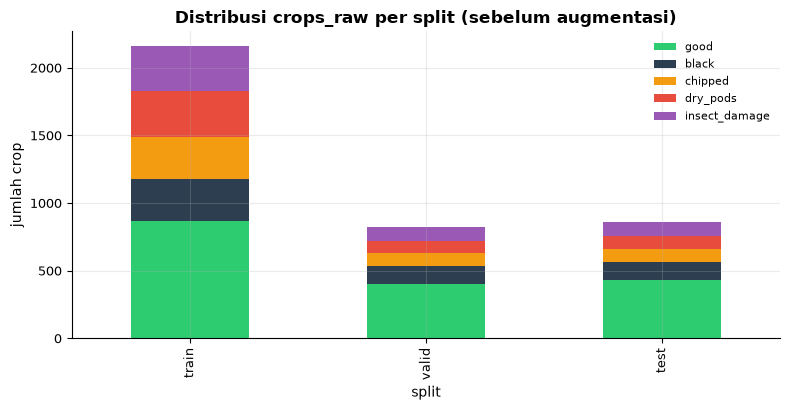

In [5]:
if not df_raw.empty:
    ax = df_raw.drop(index='TOTAL')[CLASS_NAMES].plot(
        kind='bar', stacked=True, figsize=(8, 4.2),
        color=[CLASS_COLORS[n] for n in CLASS_NAMES],
    )
    ax.set_title('Distribusi crops_raw per split (sebelum augmentasi)')
    ax.set_ylabel('jumlah crop')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 3. Augmentasi offline → `crops`

`clean=True` mengosongkan folder tujuan lebih dulu. Itu wajib saat dataset baru diganti: nama berkas Roboflow memuat hash versi, jadi crop versi lama **tidak** tertimpa dan akan mencemari split.

In [6]:
CLEAN = True  # set False bila ingin menambah tanpa mengosongkan

aug_results = build_dataset(
    input_root=CROPS_RAW_DIR,
    output_root=CROPS_DIR,
    augment_splits=AUGMENT_SPLITS,
    copy_splits=COPY_SPLITS,
    multipliers=AUGMENTATION_MULTIPLIERS,
    random_seed=RANDOM_SEED,
    class_names=CLASS_NAMES,
    clean=CLEAN,
)

print(format_augmentation_report(aug_results, class_names=CLASS_NAMES))

Augmentation Report

[train] (augmented)
  good               868 ->    868 (multiplier: 1x)
  black              309 ->    927 (multiplier: 3x)
  chipped            315 ->    945 (multiplier: 3x)
  dry_pods           338 ->  1,014 (multiplier: 3x)
  insect_damage      332 ->    996 (multiplier: 3x)
  TOTAL            2,162 ->  4,750
  (menghapus 4,750 file lama sebelum menulis)
  balance before : 1.0 : 0.4 : 0.4 : 0.4 : 0.4
  balance after  : 0.9 : 0.9 : 0.9 : 1.0 : 1.0

[valid] (copied)
  good               404 ->    404 (multiplier: 1x)
  black              133 ->    133 (multiplier: 1x)
  chipped             93 ->     93 (multiplier: 1x)
  dry_pods            93 ->     93 (multiplier: 1x)
  insect_damage       99 ->     99 (multiplier: 1x)
  TOTAL              822 ->    822
  (menghapus 822 file lama sebelum menulis)
  balance before : 1.0 : 0.3 : 0.2 : 0.2 : 0.2
  balance after  : 1.0 : 0.3 : 0.2 : 0.2 : 0.2

[test] (copied)
  good               435 ->    435 (multiplier: 1x)
  bl

## 4. Statistik `crops` (setelah augmentasi)

In [7]:
rows = []
for split, stats in aug_results.items():
    row = {'split': split, 'augmented': stats['augmented']}
    row.update({n: stats['per_class'].get(n, {}).get('output', 0) for n in CLASS_NAMES})
    row['total'] = stats['total_output']
    rows.append(row)

df_aug = pd.DataFrame(rows).set_index('split') if rows else pd.DataFrame()
df_aug

,augmented,good,black,chipped,dry_pods,insect_damage,total
split,,,,,,,
train,True,868,927,945,1014,996,4750
valid,False,404,133,93,93,99,822
test,False,435,132,96,93,107,863


## 5. Perbandingan distribusi sebelum vs sesudah (split train)

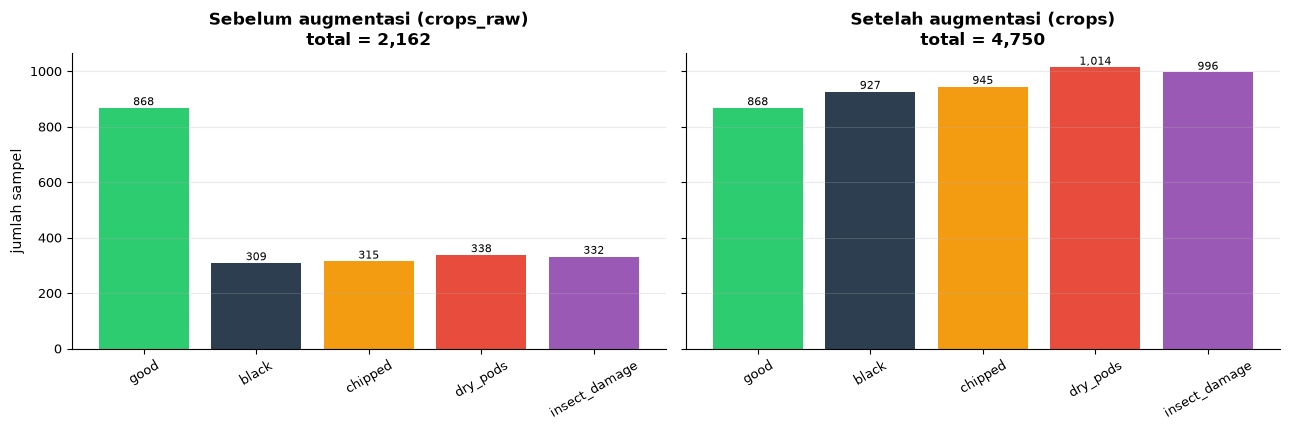

sebelum: {'total': 2162, 'majority_class': 'good', 'minority_class': 'black', 'imbalance_ratio': 2.8091, 'majority_share': 0.4015}
sesudah: {'total': 4750, 'majority_class': 'dry_pods', 'minority_class': 'good', 'imbalance_ratio': 1.1682, 'majority_share': 0.2135}


In [8]:
if 'train' in aug_results:
    per_class = aug_results['train']['per_class']
    before = [per_class.get(n, {}).get('original', 0) for n in CLASS_NAMES]
    after = [per_class.get(n, {}).get('output', 0) for n in CLASS_NAMES]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
    colors = class_palette(CLASS_NAMES)
    for ax, values, title in (
        (axes[0], before, 'Sebelum augmentasi (crops_raw)'),
        (axes[1], after, 'Setelah augmentasi (crops)'),
    ):
        ax.bar(CLASS_NAMES, values, color=colors)
        ax.set_title(f'{title}\ntotal = {sum(values):,}')
        ax.tick_params(axis='x', rotation=30)
        for i, v in enumerate(values):
            ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
    axes[0].set_ylabel('jumlah sampel')
    fig.tight_layout()
    plt.show()

    print('sebelum:', describe_imbalance(dict(zip(CLASS_NAMES, before))))
    print('sesudah:', describe_imbalance(dict(zip(CLASS_NAMES, after))))

## 6. Verifikasi visual — overlay bounding box pada foto asli

Periksa apakah warna kotak cocok dengan kondisi biji di dalamnya. Kalau `black` menandai biji yang jelas utuh, berarti `class_id` tertukar saat anotasi — perbaiki di Roboflow, jangan dilanjutkan ke pelatihan.

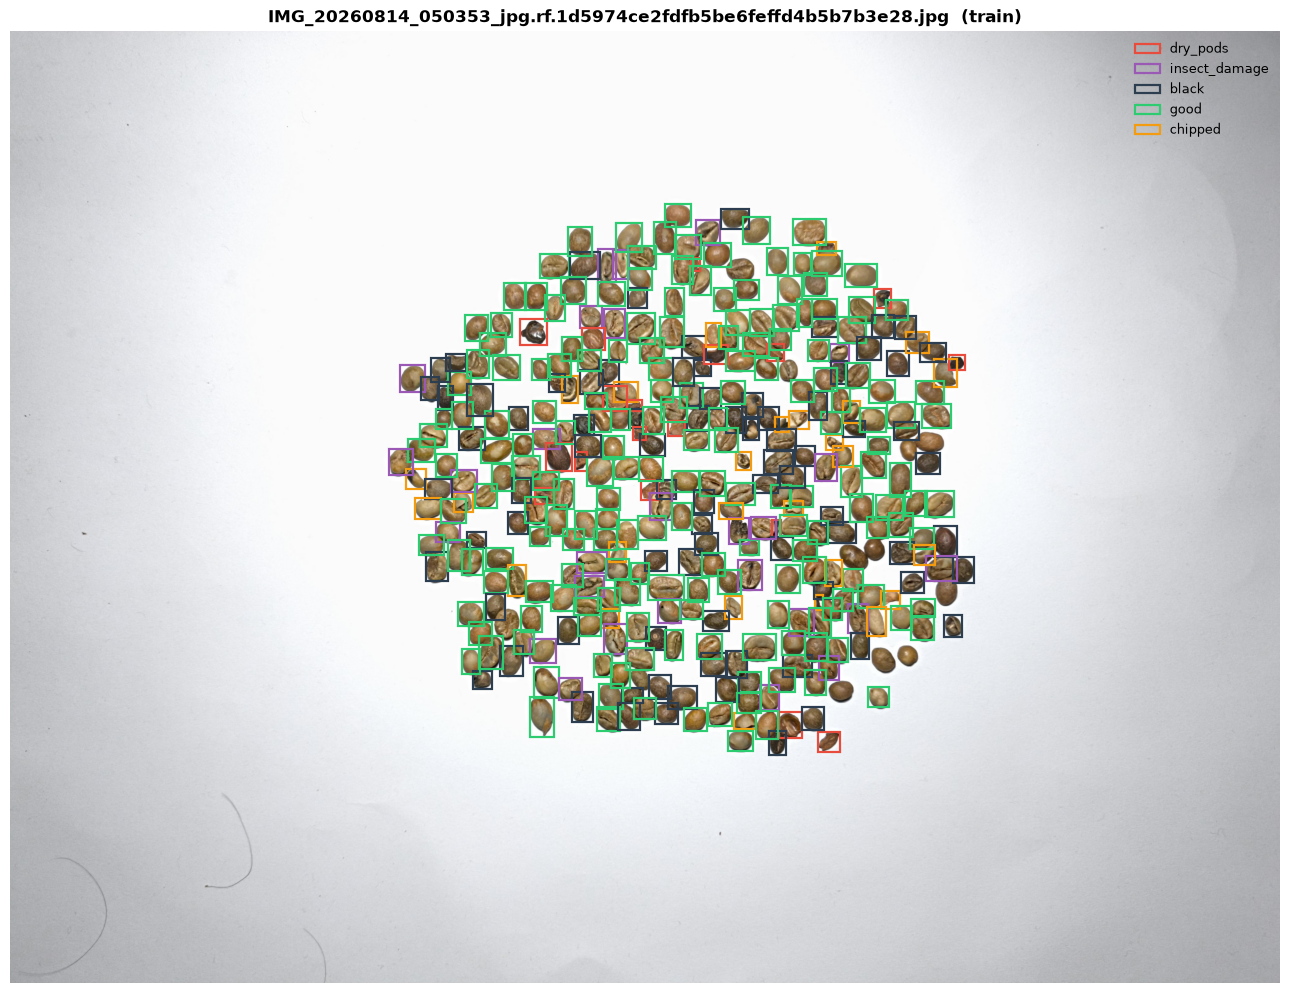

In [9]:
SPLIT_PREVIEW = 'train'
IMAGE_EXTS = ('.jpg', '.jpeg', '.png')

image_paths = sorted(
    p for p in (ANNOTATED_DATA_DIR / SPLIT_PREVIEW / 'images').glob('*')
    if p.suffix.lower() in IMAGE_EXTS
)

if image_paths:
    image_path = image_paths[0]
    label_path = ANNOTATED_DATA_DIR / SPLIT_PREVIEW / 'labels' / f'{image_path.stem}.txt'

    with Image.open(image_path) as im:
        width, height = im.size
        fig, ax = plt.subplots(figsize=(13, 10))
        ax.imshow(im)

    seen = set()
    for line in label_path.read_text(encoding='utf-8').splitlines():
        if not line.strip():
            continue
        cid, xc, yc, bw, bh = line.split()
        cid = int(float(cid))
        if not 0 <= cid < len(CLASS_NAMES):
            continue
        name = CLASS_NAMES[cid]
        x1 = (float(xc) - float(bw) / 2) * width
        y1 = (float(yc) - float(bh) / 2) * height
        ax.add_patch(
            patches.Rectangle(
                (x1, y1), float(bw) * width, float(bh) * height,
                linewidth=1.6, edgecolor=CLASS_COLORS[name], facecolor='none',
                label=name if name not in seen else None,
            )
        )
        seen.add(name)

    ax.set_title(f'{image_path.name}  ({SPLIT_PREVIEW})')
    ax.axis('off')
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()
else:
    print('Tidak ada citra untuk diperiksa.')

## 7. Verifikasi visual — grid sampel crop per kelas

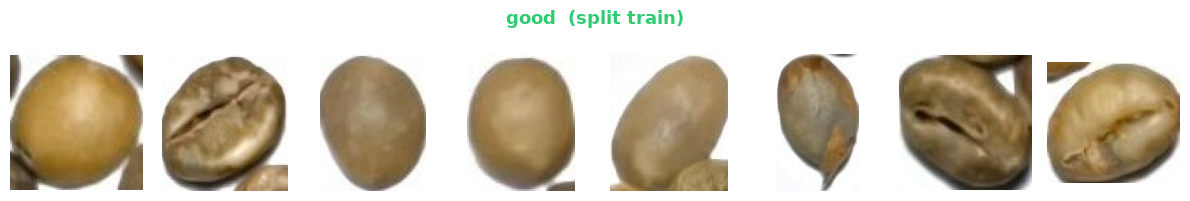

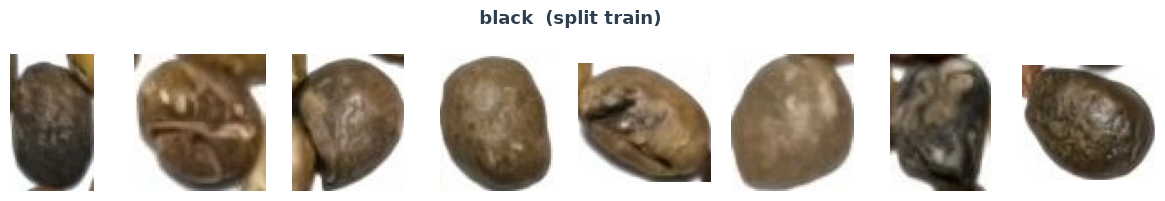

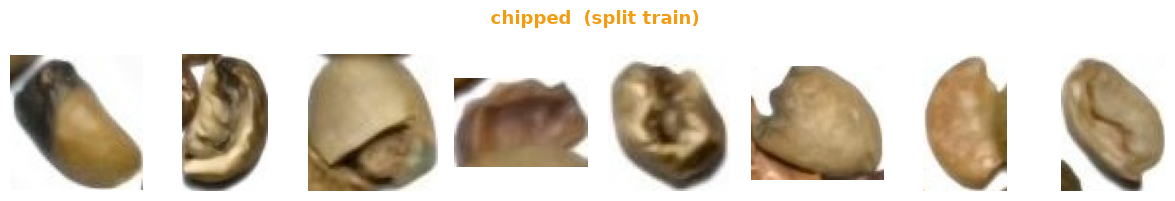

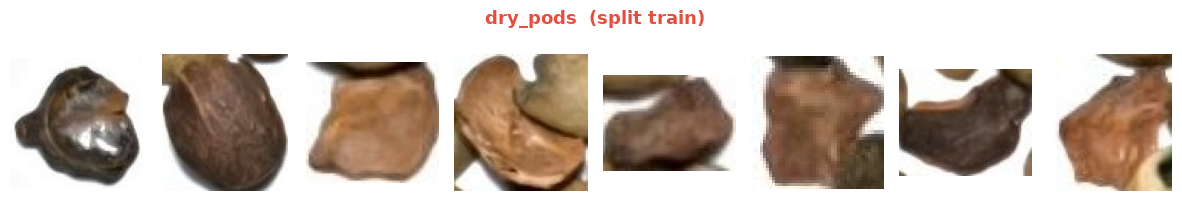

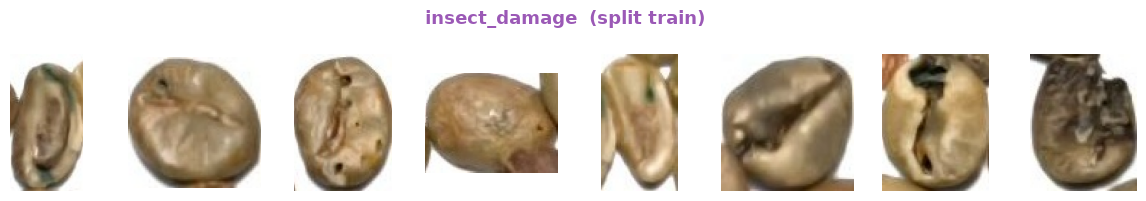

In [10]:
N_SHOW = 8

for class_name in CLASS_NAMES:
    crop_paths = sorted((CROPS_RAW_DIR / SPLIT_PREVIEW / class_name).glob('*.jpg'))[:N_SHOW]
    if not crop_paths:
        print(f'{class_name}: tidak ada crop di split {SPLIT_PREVIEW}')
        continue

    fig, axes = plt.subplots(1, len(crop_paths), figsize=(1.5 * len(crop_paths), 2.0))
    axes = [axes] if len(crop_paths) == 1 else list(axes)
    for ax, path in zip(axes, crop_paths):
        with Image.open(path) as im:
            ax.imshow(im)
        ax.axis('off')
    fig.suptitle(f'{class_name}  (split {SPLIT_PREVIEW})', color=CLASS_COLORS[class_name])
    plt.tight_layout()
    plt.show()

## 8. Verifikasi augmentasi — asli vs varian

Varian harus masih terlihat seperti biji yang sama: kalau rotasi/warnanya terlalu ekstrem sampai jenis cacatnya tidak lagi terbaca, augmentasinya justru menambah label yang salah.

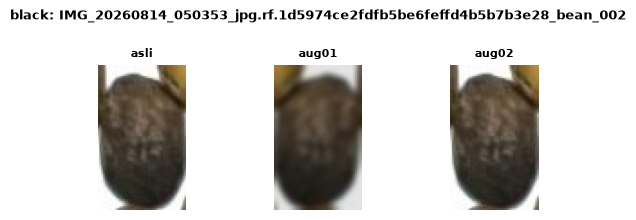

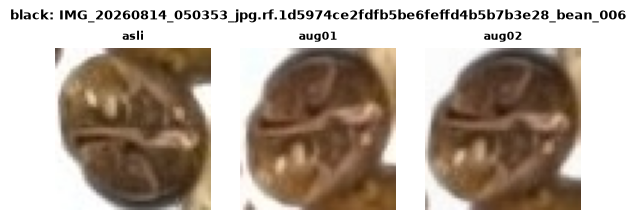

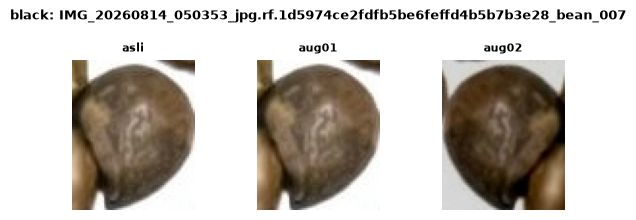

In [11]:
AUG_CLASS = CLASS_NAMES[1]  # salah satu kelas minoritas yang di-oversample

originals = sorted((CROPS_DIR / 'train' / AUG_CLASS).glob('*_orig.jpg'))[:3]
if originals:
    for orig in originals:
        stem = orig.stem.removesuffix('_orig')
        variants = sorted((CROPS_DIR / 'train' / AUG_CLASS).glob(f'{stem}_aug*.jpg'))
        paths = [orig, *variants]

        fig, axes = plt.subplots(1, len(paths), figsize=(1.9 * len(paths), 2.2))
        axes = [axes] if len(paths) == 1 else list(axes)
        for ax, path in zip(axes, paths):
            with Image.open(path) as im:
                ax.imshow(im)
            ax.set_title('asli' if path.stem.endswith('_orig') else path.stem[-5:], fontsize=8)
            ax.axis('off')
        fig.suptitle(f'{AUG_CLASS}: {stem}', fontsize=9)
        plt.tight_layout()
        plt.show()
else:
    print(f'Belum ada hasil augmentasi untuk kelas {AUG_CLASS}.')

## 9. Cek kebersihan valid & test

Tidak boleh ada berkas `_aug*` di valid/test. Kalau ada, metrik evaluasi mengukur citra buatan dan hasilnya tidak sah.

In [12]:
for split in COPY_SPLITS:
    aug_files = list((CROPS_DIR / split).glob('*/*_aug*.jpg'))
    status = f'MASALAH: {len(aug_files)} citra teraugmentasi' if aug_files else 'bersih'
    n_total = len(list((CROPS_DIR / split).glob('*/*.jpg')))
    print(f'{split:6} {n_total:>6,} crop | {status}')

print()
print('Langkah berikutnya: notebook 03-05 (pelatihan) atau')
print('  python -m scripts.train --model resnet50')

valid     822 crop | bersih
test      863 crop | bersih

Langkah berikutnya: notebook 03-05 (pelatihan) atau
  python -m scripts.train --model resnet50
